<a href="https://colab.research.google.com/github/asema405/Maachine_Learning/blob/main/ML_PR2_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations

print("Все библиотеки успешно загружены!")

Все библиотеки успешно загружены!


In [2]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"

df = pd.read_csv(url)

print("Датасет успешно загружен!")
print("Первые 5 строк:")
display(df.head())

Датасет успешно загружен!
Первые 5 строк:


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])
print("Размер таблицы:", df.shape)

Количество строк: 244
Количество столбцов: 7
Размер таблицы: (244, 7)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   total_bill  244 non-null    float64
 1   tip         244 non-null    float64
 2   sex         244 non-null    object 
 3   smoker      244 non-null    object 
 4   day         244 non-null    object 
 5   time        244 non-null    object 
 6   size        244 non-null    int64  
dtypes: float64(2), int64(1), object(4)
memory usage: 13.5+ KB


In [5]:
print("Количество пропусков по столбцам:")
display(df.isnull().sum())

print("Общее количество пропусков:", df.isnull().sum().sum())

Количество пропусков по столбцам:


,0
total_bill,0
tip,0
sex,0
smoker,0
day,0
time,0
size,0


Общее количество пропусков: 0


In [6]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df.select_dtypes(exclude=np.number).columns.tolist()

print("Числовые признаки:")
print(numeric_cols)

print("\nКатегориальные признаки:")
print(categorical_cols)

Числовые признаки:
['total_bill', 'tip', 'size']

Категориальные признаки:
['sex', 'smoker', 'day', 'time']


In [7]:
display(df.describe())

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [8]:
display(df.describe(include="object"))

,sex,smoker,day,time
count,244,244,244,244
unique,2,2,4,2
top,Male,No,Sat,Dinner
freq,157,151,87,176


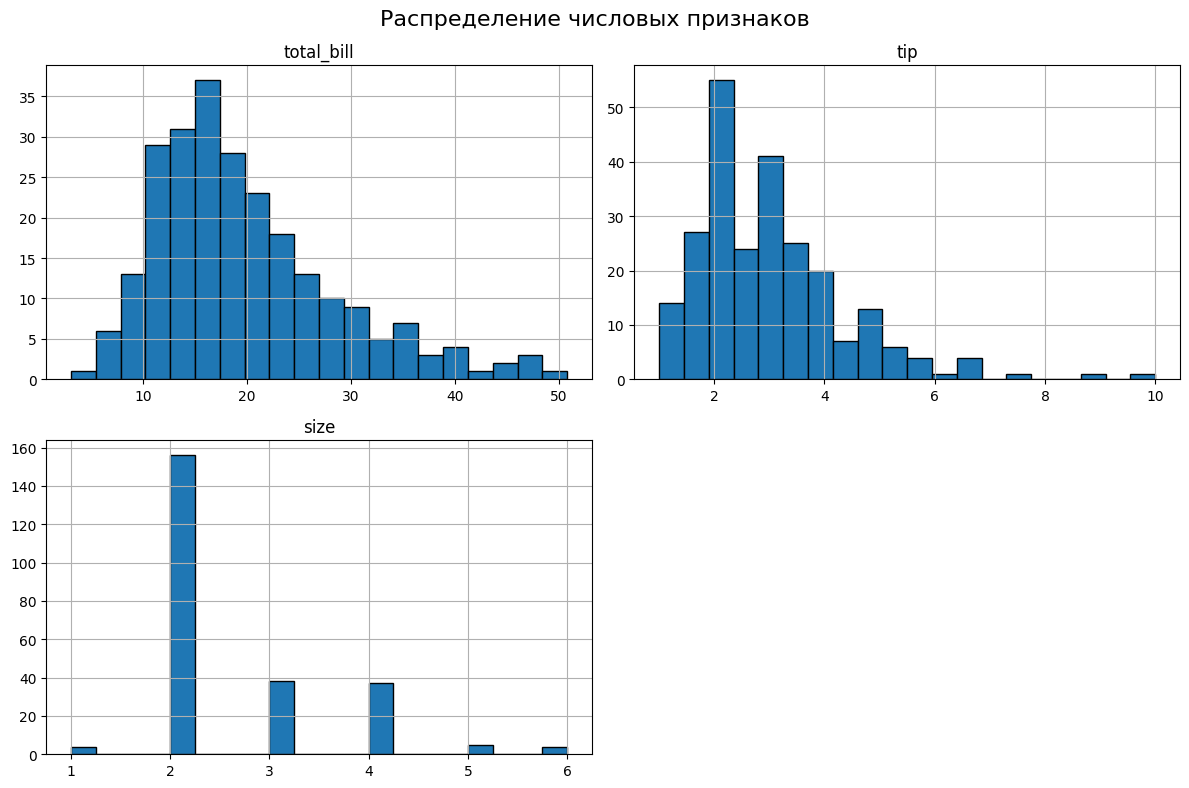

In [9]:
df[numeric_cols].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Распределение числовых признаков", fontsize=16)
plt.tight_layout()
plt.show()

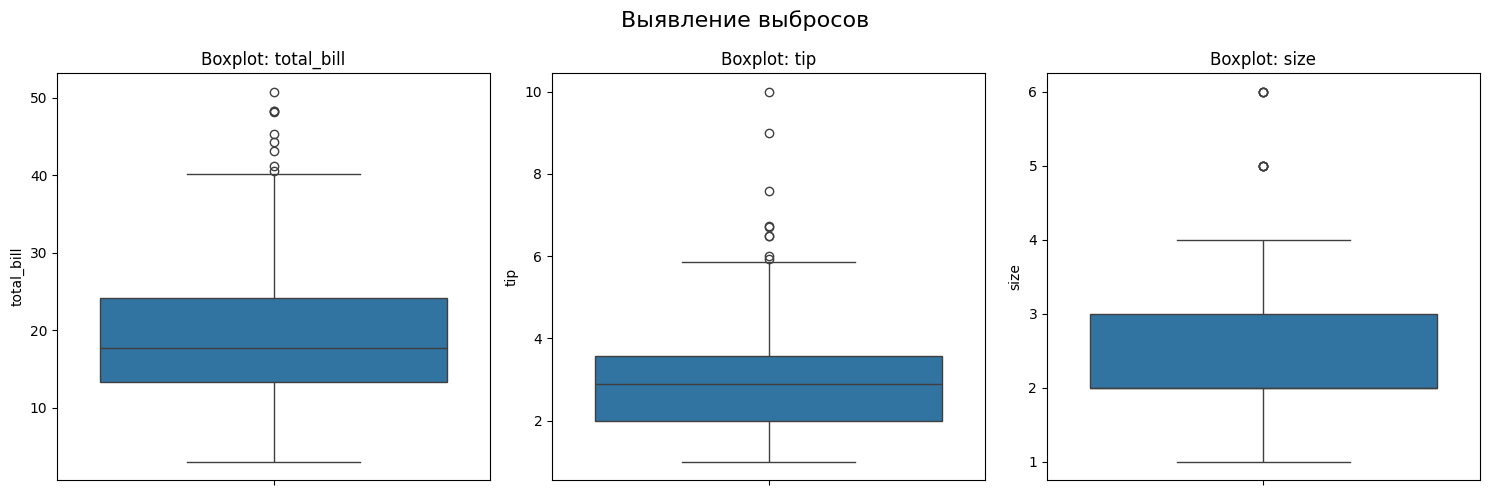

In [10]:
fig, axes = plt.subplots(
    1, len(numeric_cols),
    figsize=(15, 5)
)

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot: {col}")
    ax.set_ylabel(col)

plt.suptitle("Выявление выбросов", fontsize=16)
plt.tight_layout()
plt.show()

In [11]:
outlier_results = []

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        "Признак": col,
        "Нижняя граница": lower_bound,
        "Верхняя граница": upper_bound,
        "Количество выбросов": len(outliers)
    })

outlier_df = pd.DataFrame(outlier_results)
display(outlier_df.round(2))

,Признак,Нижняя граница,Верхняя граница,Количество выбросов
0,total_bill,-2.82,40.30,9
1,tip,-0.34,5.91,9
2,size,0.50,4.50,9


In [12]:
for col in categorical_cols:
    print(f"\nРаспределение признака: {col}")
    display(df[col].value_counts().to_frame("Количество"))


Распределение признака: sex


,Количество
sex,
Male,157
Female,87



Распределение признака: smoker


,Количество
smoker,
No,151
Yes,93



Распределение признака: day


,Количество
day,
Sat,87
Sun,76
Thur,62
Fri,19



Распределение признака: time


,Количество
time,
Dinner,176
Lunch,68


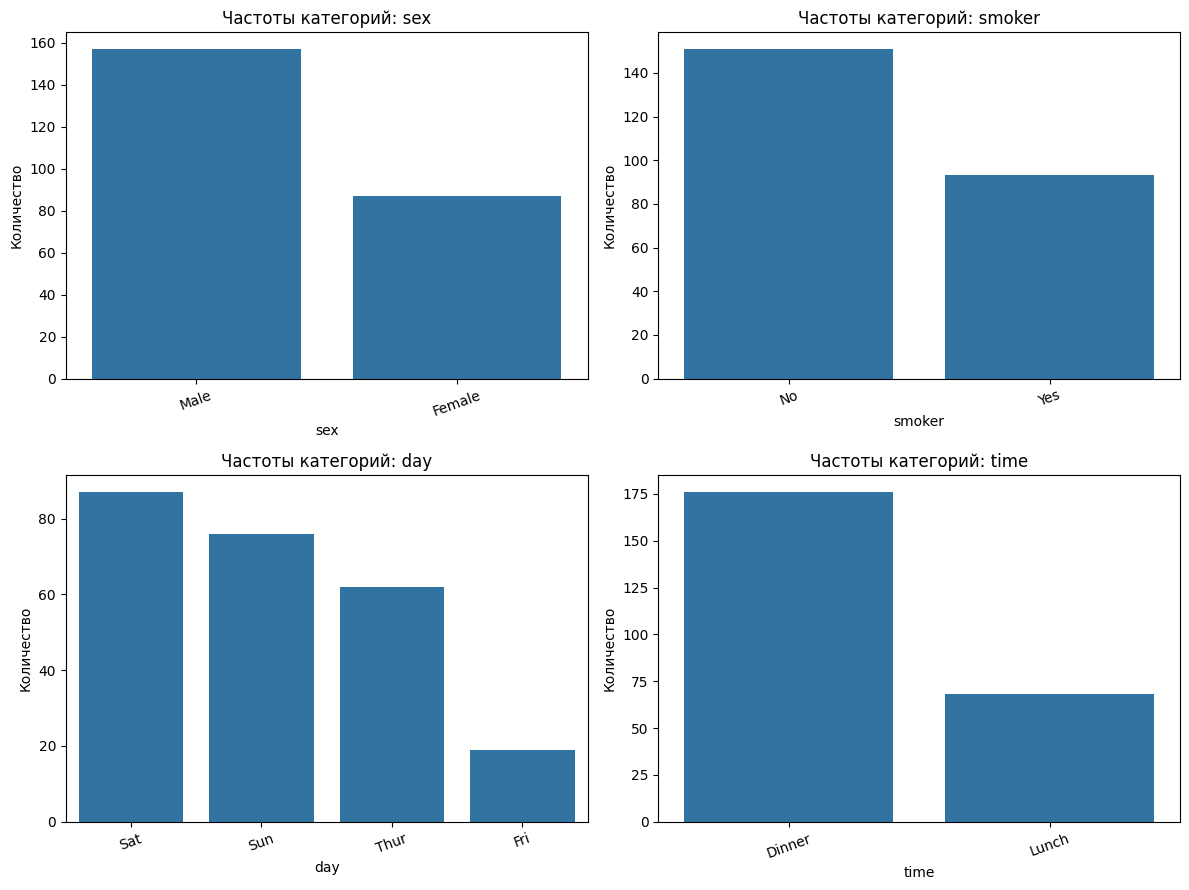

In [13]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 9)
)

for ax, col in zip(axes.flatten(), categorical_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=ax)
    ax.set_title(f"Частоты категорий: {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Количество")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

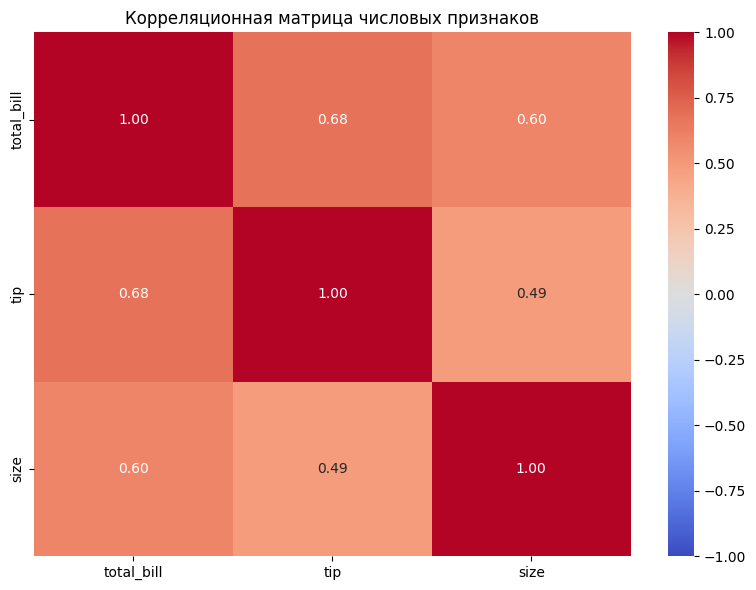

In [14]:
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Корреляционная матрица числовых признаков")
plt.tight_layout()
plt.show()

In [15]:
corr_pairs = (
    corr_matrix
    .where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    .stack()
    .reset_index()
)

corr_pairs.columns = ["Признак 1", "Признак 2", "Корреляция"]

corr_pairs["Абсолютная корреляция"] = corr_pairs["Корреляция"].abs()

corr_pairs = corr_pairs.sort_values(
    "Абсолютная корреляция",
    ascending=False
)

display(corr_pairs.round(3))

,Признак 1,Признак 2,Корреляция,Абсолютная корреляция
0,total_bill,tip,0.676,0.676
1,total_bill,size,0.598,0.598
2,tip,size,0.489,0.489


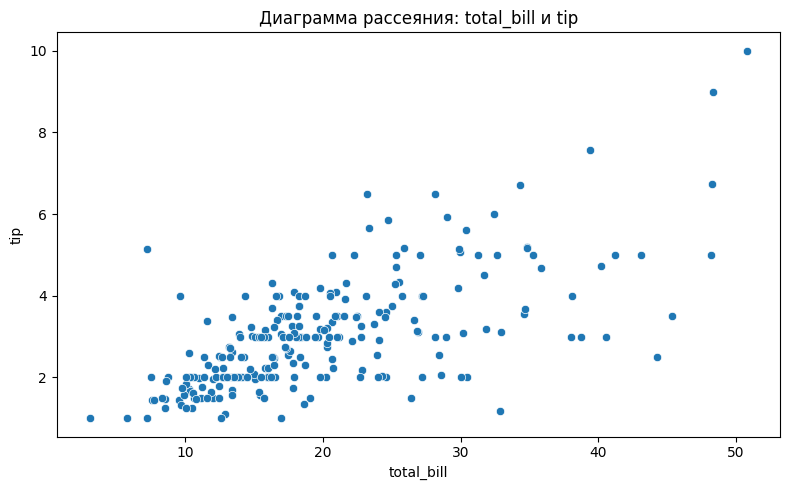

Выбранная пара: total_bill и tip
Коэффициент корреляции: 0.676


In [16]:
if not corr_pairs.empty:
    best_pair = corr_pairs.iloc[0]

    x_col = best_pair["Признак 1"]
    y_col = best_pair["Признак 2"]

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=df,
        x=x_col,
        y=y_col
    )

    plt.title(f"Диаграмма рассеяния: {x_col} и {y_col}")
    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.tight_layout()
    plt.show()

    print("Выбранная пара:", x_col, "и", y_col)
    print("Коэффициент корреляции:", round(best_pair["Корреляция"], 3))

In [17]:
for col in categorical_cols:
    print(f"\nПризнак: {col}")
    display(
        (df[col].value_counts(normalize=True) * 100)
        .round(2)
        .to_frame("Доля, %")
    )


Признак: sex


,"Доля, %"
sex,
Male,64.34
Female,35.66



Признак: smoker


,"Доля, %"
smoker,
No,61.89
Yes,38.11



Признак: day


,"Доля, %"
day,
Sat,35.66
Sun,31.15
Thur,25.41
Fri,7.79



Признак: time


,"Доля, %"
time,
Dinner,72.13
Lunch,27.87


## Итоговый отчет по результатам EDA

1. **Общая структура данных.** Датасет содержит 244 строки и 7 столбцов. В нём представлены числовые и категориальные признаки.

2. **Пропущенные значения.** Проверка `isnull().sum()` позволяет определить количество пропусков в каждом столбце. В исходном датасете `tips` пропущенные значения отсутствуют.

3. **Распределение числовых признаков.** Гистограммы показывают распределение сумм счетов, чаевых и количества посетителей. Для выявления необычных значений дополнительно использованы boxplot.

4. **Потенциальные выбросы.** Для числовых признаков применён метод межквартильного размаха (IQR). Обнаруженные значения нельзя автоматически считать ошибками, поэтому перед удалением необходимо изучить их происхождение.

5. **Категориальные признаки.** Столбчатые диаграммы показывают частоты категорий пола, наличия курения, дня недели и времени приёма пищи. Редкие категории следует учитывать при дальнейшем анализе.

6. **Корреляции между числовыми признаками.** Корреляционная матрица и диаграмма рассеяния используются для выявления связей между суммой счёта, чаевыми и количеством посетителей. Корреляция не означает причинно-следственную связь.

7. **План дальнейшей обработки.** Перед построением модели необходимо проверить потенциальные выбросы, определить подход к обработке категориальных признаков и оценить необходимость масштабирования числовых данных. Удалять данные без обоснования не следует.

### Вывод

В ходе разведочного анализа изучены структура датасета, типы признаков, пропущенные значения, распределения, потенциальные выбросы, частоты категорий и корреляции. Полученные результаты помогут подготовить данные к дальнейшему анализу и машинному обучению.